Phase 8: Data Visualization

Reducing Customer Churn at Meridian Retail Group

Objective: Communicate the findings from Phase 7 through clear, informative, and properly labelled visualizations.

Requirements:

Produce at least four static visualizations using Matplotlib.

Produce at least two interactive visualizations using Plotly.

Give every chart a meaningful title, appropriate labels, and a 1–2 sentence caption explaining the insight it supports.

Save chart outputs in the project's designated output folder.

Use the cleaned datasets and analytical results consistently with Phase 7.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Meridian_Churn_Capstone"
)

CLEANED_DIR = PROJECT_DIR / "Data" / "Cleaned"
OUTPUT_DIR = PROJECT_DIR / "Outputs" / "Phase_08_Visualizations"

print("Project folder exists:", PROJECT_DIR.exists())
print("Cleaned data folder exists:", CLEANED_DIR.exists())

if CLEANED_DIR.exists():
    print("\nFiles in cleaned data folder:")
    for file in sorted(CLEANED_DIR.glob("*.csv")):
        print(file.name)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("\nVisualization output folder ready:", OUTPUT_DIR)

Project folder exists: True
Cleaned data folder exists: True

Files in cleaned data folder:
customers.csv
order_items.csv
orders.csv
products.csv
support_tickets.csv

Visualization output folder ready: /content/drive/MyDrive/Meridian_Churn_Capstone/Outputs/Phase_08_Visualizations


In [3]:
# Data handling
import pandas as pd
import numpy as np

# Static visualizations
import matplotlib.pyplot as plt

# Interactive visualizations
import plotly.express as px
import plotly.graph_objects as go

# Date and file handling
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Make Matplotlib charts readable
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [4]:
# Load the five cleaned datasets

customers = pd.read_csv(CLEANED_DIR / "customers.csv")
products = pd.read_csv(CLEANED_DIR / "products.csv")
orders = pd.read_csv(CLEANED_DIR / "orders.csv")
order_items = pd.read_csv(CLEANED_DIR / "order_items.csv")
support_tickets = pd.read_csv(CLEANED_DIR / "support_tickets.csv")

# Store the datasets together for easy checking
datasets = {
    "Customers": customers,
    "Products": products,
    "Orders": orders,
    "Order Items": order_items,
    "Support Tickets": support_tickets
}

# Display each dataset's dimensions and column names
for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"{name}")
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")
    print("Column names:")
    print(df.columns.tolist())

print("\nAll five cleaned datasets loaded successfully.")


Customers
Rows: 6,090
Columns: 22
Column names:
['customer_id', 'first_name', 'last_name', 'email', 'phone', 'gender', 'date_of_birth', 'signup_date', 'state', 'city', 'membership_tier', 'preferred_channel', 'marketing_opt_in', 'referral_source', 'email_missing', 'phone_missing', 'date_of_birth_missing', 'city_missing', 'marketing_opt_in_missing', 'referral_source_missing', 'dob_before_1900_invalid', 'dob_after_snapshot_invalid']

Products
Rows: 220
Columns: 11
Column names:
['product_id', 'product_name', 'category', 'sub_category', 'brand', 'unit_cost', 'unit_price', 'launch_date', 'is_active', 'sub_category_missing', 'cost_exceeds_price_invalid']

Orders
Rows: 28,272
Columns: 12
Column names:
['order_id', 'customer_id', 'order_date', 'channel', 'order_status', 'payment_method', 'shipping_cost', 'discount_pct', 'total_amount', 'order_date_missing', 'negative_shipping_cost_invalid', 'customer_reference_missing']

Order Items
Rows: 73,465
Columns: 7
Column names:
['order_item_id', 'ord

In [5]:
# Phase 7 churn definition
SNAPSHOT_DATE = pd.Timestamp("2026-07-01")
WINDOW_START = SNAPSHOT_DATE - pd.Timedelta(days=180)

# Convert order_date to datetime
orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    errors="coerce"
)

# Identify completed orders within the observation window
valid_completed_orders = orders[
    (orders["order_status"].str.strip().str.lower() == "completed") &
    (orders["order_date"] >= WINDOW_START) &
    (orders["order_date"] < SNAPSHOT_DATE)
].copy()

# Find customers who made at least one qualifying completed order
active_customer_ids = set(
    valid_completed_orders["customer_id"].dropna().unique()
)

# Create a churn label for every customer
customer_analysis = customers.copy()

customer_analysis["churn_status"] = np.where(
    customer_analysis["customer_id"].isin(active_customer_ids),
    "Active",
    "Churned"
)

customer_analysis["churned"] = (
    customer_analysis["churn_status"] == "Churned"
).astype(int)

# Display the results
print("Snapshot date:", SNAPSHOT_DATE.date())
print("Observation window:", WINDOW_START.date(), "to", (SNAPSHOT_DATE - pd.Timedelta(days=1)).date())
print("Qualifying completed orders:", f"{len(valid_completed_orders):,}")
print("\nCustomer churn summary:")
print(customer_analysis["churn_status"].value_counts())

print(
    "\nOverall churn rate:",
    f"{customer_analysis['churned'].mean() * 100:.2f}%"
)

print(
    "\nCustomers with no qualifying completed order:",
    f"{(~customer_analysis['customer_id'].isin(active_customer_ids)).sum():,}"
)

Snapshot date: 2026-07-01
Observation window: 2026-01-02 to 2026-06-30
Qualifying completed orders: 4,778

Customer churn summary:
churn_status
Churned    4075
Active     2015
Name: count, dtype: int64

Overall churn rate: 66.91%

Customers with no qualifying completed order: 4,075


,membership_tier,total_customers,churned_customers,churn_rate_pct
1,Gold,1126,765,67.94
3,Silver,1768,1184,66.97
2,Platinum,411,274,66.67
0,Bronze,2785,1852,66.50


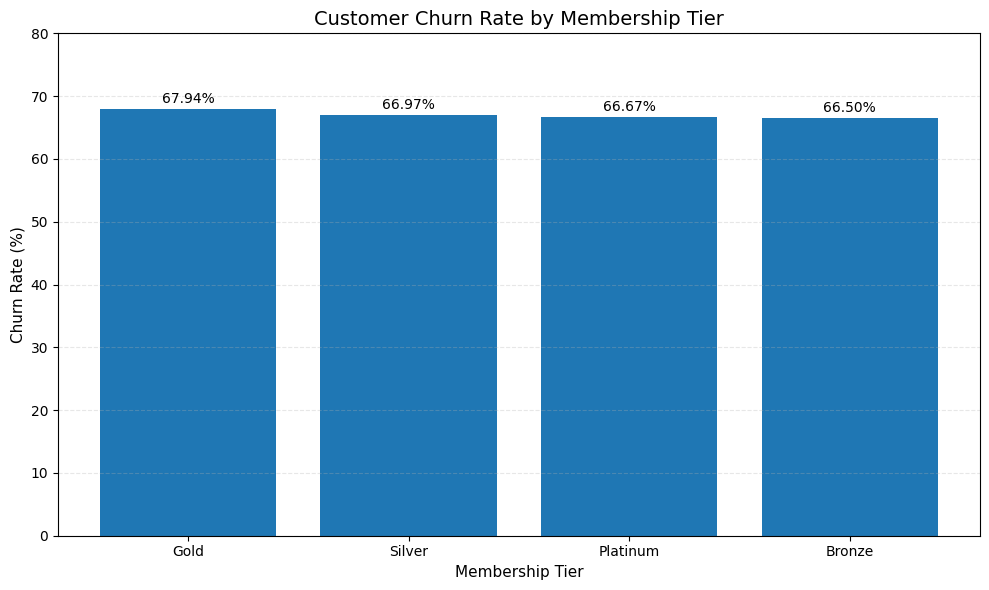

In [6]:
# Calculate churn rate by membership tier
tier_churn = (
    customer_analysis
    .groupby("membership_tier", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churned", "sum"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

tier_churn["churn_rate_pct"] = tier_churn["churn_rate"] * 100

# Sort tiers by churn rate
tier_churn = tier_churn.sort_values(
    "churn_rate_pct",
    ascending=False
)

# Display the summary table
display(
    tier_churn[
        ["membership_tier", "total_customers",
         "churned_customers", "churn_rate_pct"]
    ].round(2)
)

# Create the Matplotlib chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    tier_churn["membership_tier"].astype(str),
    tier_churn["churn_rate_pct"]
)

# Add percentage labels above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.title("Customer Churn Rate by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 80)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save the chart for the final project submission
plt.savefig(
    OUTPUT_DIR / "01_churn_by_membership_tier.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,membership_tier,total_customers,churned_customers,churn_rate_pct
1,Gold,1126,765,67.94
3,Silver,1768,1184,66.97
2,Platinum,411,274,66.67
0,Bronze,2785,1852,66.50


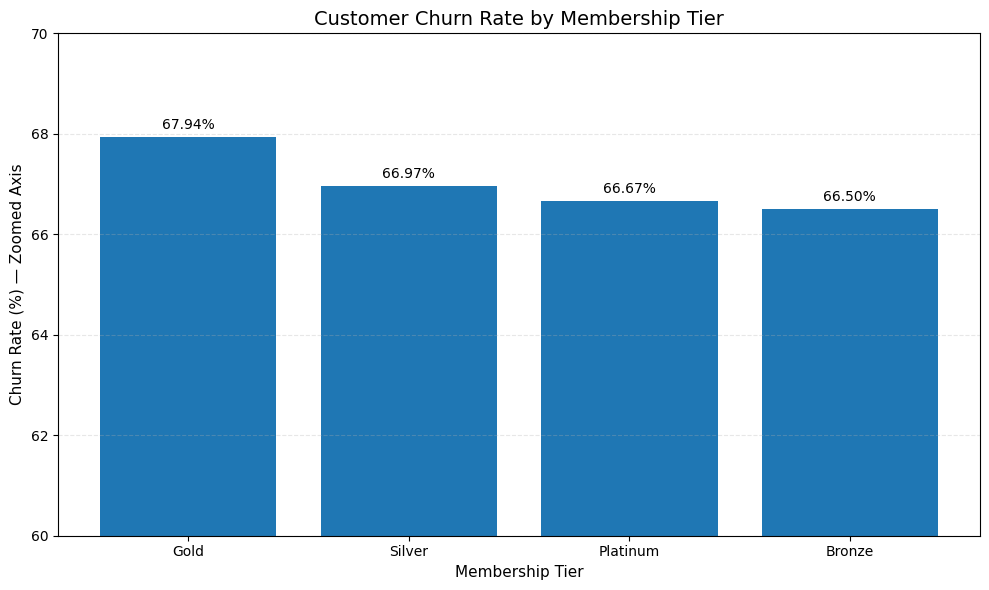

In [7]:
# Calculate churn rate by membership tier
tier_churn = (
    customer_analysis
    .groupby("membership_tier", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churned", "sum"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

tier_churn["churn_rate_pct"] = tier_churn["churn_rate"] * 100

# Sort tiers from highest to lowest churn rate
tier_churn = tier_churn.sort_values(
    "churn_rate_pct",
    ascending=False
)

# Display the summary table
display(
    tier_churn[
        [
            "membership_tier",
            "total_customers",
            "churned_customers",
            "churn_rate_pct"
        ]
    ].round(2)
)

# Create the Matplotlib chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    tier_churn["membership_tier"].astype(str),
    tier_churn["churn_rate_pct"]
)

# Add percentage labels above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.1,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Chart title and axis labels
plt.title("Customer Churn Rate by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%) — Zoomed Axis")

# Zoom in to make the small differences more visible
plt.ylim(60, 70)

# Improve readability
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save the chart to Google Drive
plt.savefig(
    OUTPUT_DIR / "01_churn_by_membership_tier.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

,preferred_channel,total_customers,churned_customers,churn_rate_pct
0,In-Store,2041,1388,68.01
1,Mobile App,2053,1369,66.68
2,Online,1996,1318,66.03


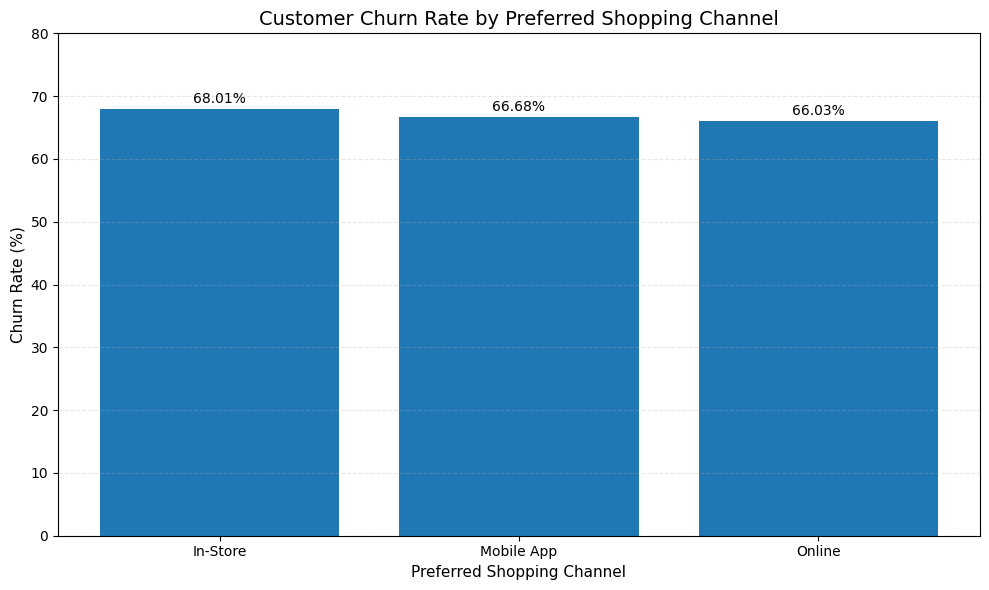

In [8]:
# Calculate churn rate by preferred shopping channel
channel_churn = (
    customer_analysis
    .groupby("preferred_channel", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churned", "sum"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

# Convert churn rate to percentage
channel_churn["churn_rate_pct"] = (
    channel_churn["churn_rate"] * 100
)

# Sort channels from highest to lowest churn rate
channel_churn = channel_churn.sort_values(
    "churn_rate_pct",
    ascending=False
)

# Display the results table
display(
    channel_churn[
        [
            "preferred_channel",
            "total_customers",
            "churned_customers",
            "churn_rate_pct"
        ]
    ].round(2)
)

# Create the chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    channel_churn["preferred_channel"].fillna("Unknown").astype(str),
    channel_churn["churn_rate_pct"]
)

# Add percentage labels above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Add chart title and labels
plt.title("Customer Churn Rate by Preferred Shopping Channel")
plt.xlabel("Preferred Shopping Channel")
plt.ylabel("Churn Rate (%)")

# Use a zero-based axis for an honest comparison
plt.ylim(0, 80)

# Improve readability
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig(
    OUTPUT_DIR / "02_churn_by_preferred_channel.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()

In [9]:
# Find each customer's most recent completed order
completed_orders = orders[
    (orders["order_status"].str.strip().str.lower() == "completed") &
    (orders["order_date"] < SNAPSHOT_DATE) &
    (orders["order_date"].notna()) &
    (orders["customer_id"].isin(customers["customer_id"]))
].copy()

last_purchase = (
    completed_orders
    .groupby("customer_id")["order_date"]
    .max()
    .reset_index()
)

last_purchase.rename(
    columns={"order_date": "last_purchase_date"},
    inplace=True
)

# Add last purchase date to the customer analysis table
customer_analysis = customer_analysis.drop(
    columns=["last_purchase_date", "recency_days"],
    errors="ignore"
)

customer_analysis = customer_analysis.merge(
    last_purchase,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Calculate recency in days
customer_analysis["recency_days"] = (
    SNAPSHOT_DATE - customer_analysis["last_purchase_date"]
).dt.days

# Display a summary
print("Recency summary by churn status:")
display(
    customer_analysis
    .groupby("churn_status")
    .agg(
        total_customers=("customer_id", "nunique"),
        customers_with_purchase=("recency_days", "count"),
        average_recency_days=("recency_days", "mean"),
        median_recency_days=("recency_days", "median")
    )
    .round(2)
)

print("\nCustomers without a recorded completed purchase:",
      customer_analysis["recency_days"].isna().sum())

Recency summary by churn status:


,total_customers,customers_with_purchase,average_recency_days,median_recency_days
churn_status,,,,
Active,2015,2015,89.33,87.00
Churned,4075,3625,515.71,454.00



Customers without a recorded completed purchase: 450


The results show that active customers made their most recent completed purchase an average of 89.33 days before the snapshot date, compared with 515.71 days for churned customers. The 450 churned customers without a recorded completed purchase have no recency value, so we must not plot them as zero days.

Recency statistics by churn status (days):


,mean,median
churn_status,,
Active,89.33,87.00
Churned,515.71,454.00


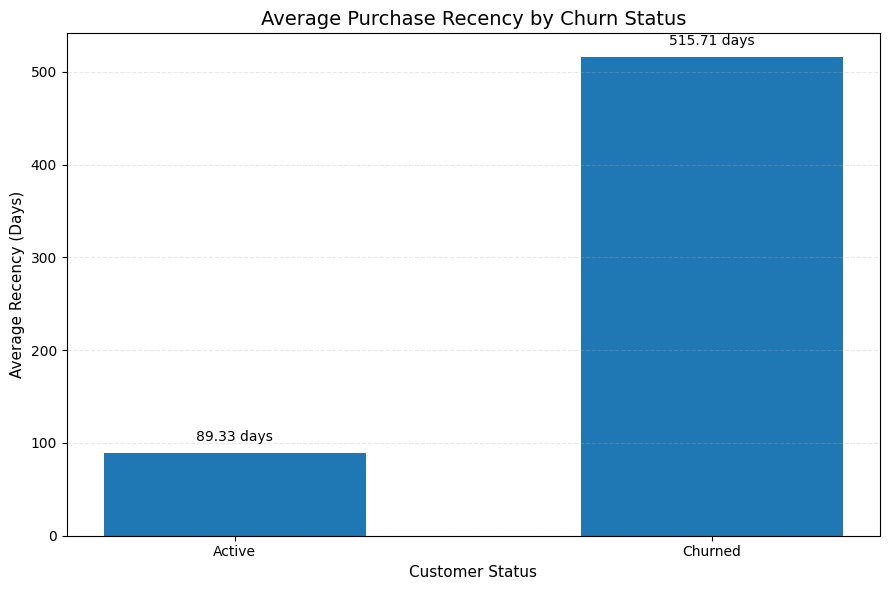

In [10]:
# Keep customers with a valid recency value
recency_data = customer_analysis[
    customer_analysis["recency_days"].notna()
].copy()

# Calculate average and median recency by churn status
recency_summary = (
    recency_data
    .groupby("churn_status")["recency_days"]
    .agg(["mean", "median"])
    .reindex(["Active", "Churned"])
)

# Display the summary
print("Recency statistics by churn status (days):")
display(recency_summary.round(2))

# Create the chart
plt.figure(figsize=(9, 6))

bars = plt.bar(
    recency_summary.index,
    recency_summary["mean"],
    width=0.55
)

# Add labels above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 10,
        f"{height:.2f} days",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title("Average Purchase Recency by Churn Status")
plt.xlabel("Customer Status")
plt.ylabel("Average Recency (Days)")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig(
    OUTPUT_DIR / "03_average_recency_by_churn_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Customers classified as churned had a substantially higher average purchase recency (515.71 days) than active customers (89.33 days). This is consistent with the inactivity-based churn definition used in this project; therefore, the difference is descriptive and should not be interpreted as independent evidence that recency causes churn.The 450 churned customers with no recorded completed purchase are excluded from the recency averages because their recency is unknown, not zero.

Figure 3: Average Purchase Recency by Churn Status

Customers classified as churned had a substantially higher average purchase recency of 515.71 days, compared with 89.33 days for active customers. This difference is consistent with the project's inactivity-based churn definition and should be interpreted descriptively rather than as evidence that recency independently causes churn.

Monthly completed orders — most recent 12 months:


,order_month,completed_orders,unique_customers,total_order_value
0,2026-01-01,771,573,"1,188,106.18"
1,2026-02-01,749,568,"1,214,240.16"
2,2026-03-01,1011,676,"1,584,471.37"
3,2026-04-01,953,617,"1,486,554.97"
4,2026-05-01,824,466,"1,267,295.10"
5,2026-06-01,470,214,"720,579.91"


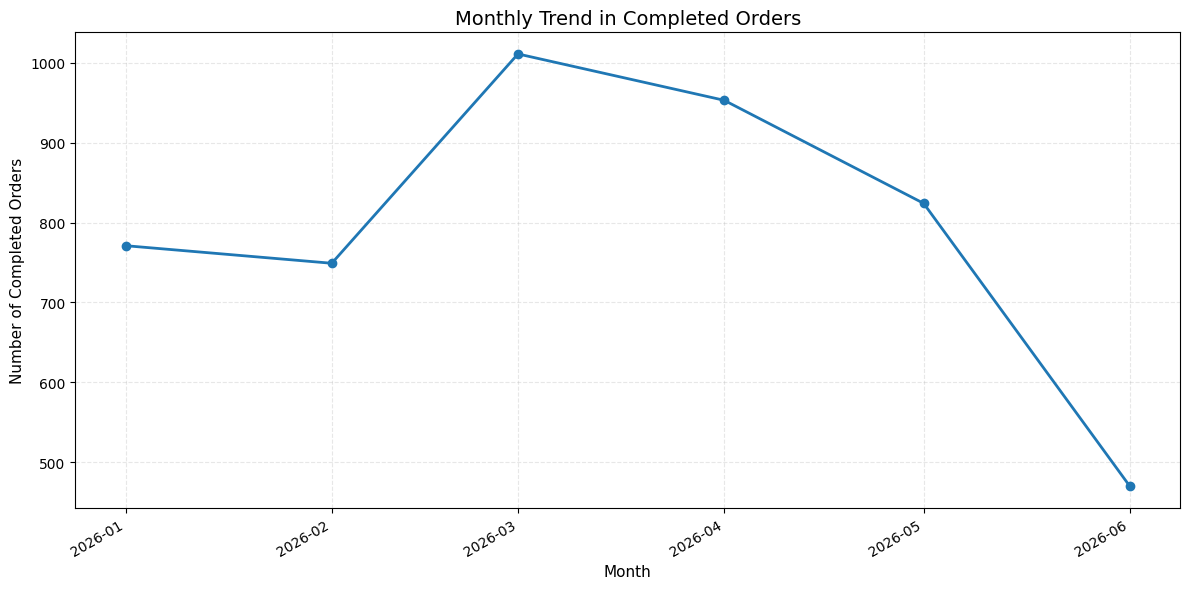

In [11]:
# Extract year and month from completed order dates
monthly_orders = valid_completed_orders.copy()

monthly_orders["order_month"] = (
    monthly_orders["order_date"].dt.to_period("M")
)

# Count completed orders each month
monthly_summary = (
    monthly_orders
    .groupby("order_month")
    .agg(
        completed_orders=("order_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        total_order_value=("total_amount", "sum")
    )
    .reset_index()
)

# Convert monthly periods into timestamps for plotting
monthly_summary["order_month"] = (
    monthly_summary["order_month"].dt.to_timestamp()
)

# Display the most recent 12 months
print("Monthly completed orders — most recent 12 months:")
display(monthly_summary.tail(12).round(2))

# Create the line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_summary["order_month"],
    monthly_summary["completed_orders"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Trend in Completed Orders")
plt.xlabel("Month")
plt.ylabel("Number of Completed Orders")
plt.grid(True, linestyle="--", alpha=0.3)

plt.gcf().autofmt_xdate()
plt.tight_layout()

# Save the chart
plt.savefig(
    OUTPUT_DIR / "04_monthly_completed_order_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Figure 4: Monthly Trend in Completed Orders

Completed-order volume peaked at 1,011 orders in March 2026, then declined to 470 in June 2026. This pattern indicates a recent reduction in recorded completed-order activity; however, June's reporting completeness should be verified before concluding that the decline reflects a genuine reduction in business activity.

In [12]:
# Calculate churn by referral source
referral_churn = (
    customer_analysis
    .groupby("referral_source", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churned", "sum"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

referral_churn["referral_source"] = (
    referral_churn["referral_source"]
    .fillna("Unknown / Not recorded")
)

referral_churn["churn_rate_pct"] = (
    referral_churn["churn_rate"] * 100
)

referral_churn = referral_churn.sort_values(
    "churn_rate_pct",
    ascending=False
)

# Display the summary table
display(
    referral_churn[
        [
            "referral_source",
            "total_customers",
            "churned_customers",
            "churn_rate_pct"
        ]
    ].round(2)
)

# Create an interactive Plotly bar chart
fig = px.bar(
    referral_churn,
    x="referral_source",
    y="churn_rate_pct",
    hover_data={
        "total_customers": True,
        "churned_customers": True,
        "churn_rate_pct": ":.2f",
        "referral_source": True
    },
    title="Interactive Customer Churn Rate by Referral Source",
    labels={
        "referral_source": "Referral Source",
        "churn_rate_pct": "Churn Rate (%)"
    }
)

fig.update_layout(
    xaxis_tickangle=-35,
    yaxis_range=[0, 80],
    template="plotly_white"
)

fig.show()

# Save the interactive chart as an HTML file
fig.write_html(
    str(OUTPUT_DIR / "05_interactive_churn_by_referral_source.html")
)

print("Interactive chart saved successfully.")

,referral_source,total_customers,churned_customers,churn_rate_pct
1,Friend Referral,614,423,68.89
4,Social Media,650,445,68.46
7,Unknown / Not recorded,1705,1166,68.39
5,Tv Ad,635,425,66.93
6,Walk-In,649,429,66.10
3,Search Engine,604,396,65.56
0,Email Campaign,604,394,65.23
2,Influencer,629,397,63.12


Interactive chart saved successfully.


**Figure 5: Interactive Customer Churn Rate by Referral Source**

Customers recorded as coming through friend referrals had the highest observed churn rate (68.89%), while customers attributed to influencers had the lowest (63.12%). In addition, 1,705 customers had an unknown or unrecorded referral source. These descriptive results identify areas for further investigation but do not establish that any referral channel causes churn.

In [13]:
# Build purchase frequency and monetary value per customer
completed_before_snapshot = orders[
    (orders["order_status"].str.strip().str.lower() == "completed") &
    (orders["order_date"].notna()) &
    (orders["order_date"] < SNAPSHOT_DATE) &
    (orders["customer_id"].isin(customers["customer_id"]))
].copy()

customer_rfm = (
    completed_before_snapshot
    .groupby("customer_id")
    .agg(
        frequency=("order_id", "nunique"),
        monetary=("total_amount", "sum")
    )
    .reset_index()
)

# Include every customer, including customers without completed orders
customer_rfm = customer_analysis[
    ["customer_id", "churn_status"]
].merge(
    customer_rfm,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

customer_rfm["frequency"] = customer_rfm["frequency"].fillna(0)
customer_rfm["monetary"] = customer_rfm["monetary"].fillna(0)

# Display a small summary for checking
print("Customer purchase frequency and monetary summary:")
display(
    customer_rfm.groupby("churn_status")
    .agg(
        customers=("customer_id", "nunique"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean")
    )
    .round(2)
)

# Create the interactive scatter plot
fig = px.scatter(
    customer_rfm,
    x="frequency",
    y="monetary",
    color="churn_status",
    hover_data=["customer_id"],
    title="Interactive Customer Purchase Frequency vs Spending",
    labels={
        "frequency": "Number of Completed Orders",
        "monetary": "Total Completed-Order Value",
        "churn_status": "Customer Status"
    },
    opacity=0.65
)

fig.update_layout(
    template="plotly_white"
)

fig.show()

# Save the interactive chart
fig.write_html(
    str(OUTPUT_DIR / "06_interactive_frequency_vs_spending.html")
)

print("Second interactive Plotly chart saved successfully.")

Customer purchase frequency and monetary summary:


,customers,average_frequency,average_monetary
churn_status,,,
Active,2015,4.80,"7,430.43"
Churned,4075,3.78,"5,792.67"


Second interactive Plotly chart saved successfully.


The interactive scatter plot shows that active customers had higher average purchase frequency (4.80 orders) and total completed-order value (7,430.43) than churned customers (3.78 orders and 5,792.67, respectively). These descriptive differences suggest that purchasing frequency and spending may help distinguish customer groups, although they do not establish causation and should be interpreted in light of the observation period and churn definition.

In [14]:
print("Phase 8 output files:")

for f in sorted(OUTPUT_DIR.iterdir()):
    if f.is_file():
        print(f"{f.name} — {f.stat().st_size:,} bytes")

Phase 8 output files:
01_churn_by_membership_tier.png — 125,493 bytes
02_churn_by_preferred_channel.png — 128,283 bytes
03_average_recency_by_churn_status.png — 117,369 bytes
04_monthly_completed_order_trend.png — 194,770 bytes
05_interactive_churn_by_referral_source.html — 4,567,642 bytes
06_interactive_frequency_vs_spending.html — 4,741,293 bytes


In [15]:
# Use all completed orders before the snapshot date
all_completed_orders = orders.copy()

all_completed_orders["order_date"] = pd.to_datetime(
    all_completed_orders["order_date"],
    errors="coerce"
)

all_completed_orders = all_completed_orders[
    (all_completed_orders["order_status"].str.lower() == "completed")
    & (all_completed_orders["order_date"] < SNAPSHOT_DATE)
    & (all_completed_orders["order_date"].notna())
].copy()

# Group completed orders by month
all_completed_orders["order_month"] = (
    all_completed_orders["order_date"].dt.to_period("M").dt.to_timestamp()
)

monthly_history = (
    all_completed_orders
    .groupby("order_month")
    .agg(
        completed_orders=("order_id", "nunique"),
        customers=("customer_id", "nunique"),
        total_order_value=("total_amount", "sum")
    )
    .reset_index()
)

print("Full historical monthly trend:")
print(monthly_history.head())
print("\nNumber of months:", len(monthly_history))
print("First month:", monthly_history["order_month"].min())
print("Last month:", monthly_history["order_month"].max())

Full historical monthly trend:
  order_month  completed_orders  customers  total_order_value
0  2020-09-01                 4          4           3,240.49
1  2020-10-01                 7          6           7,268.74
2  2020-11-01                11         10           7,773.03
3  2020-12-01                16         16          28,811.11
4  2021-01-01                20         19          30,773.47

Number of months: 70
First month: 2020-09-01 00:00:00
Last month: 2026-06-01 00:00:00


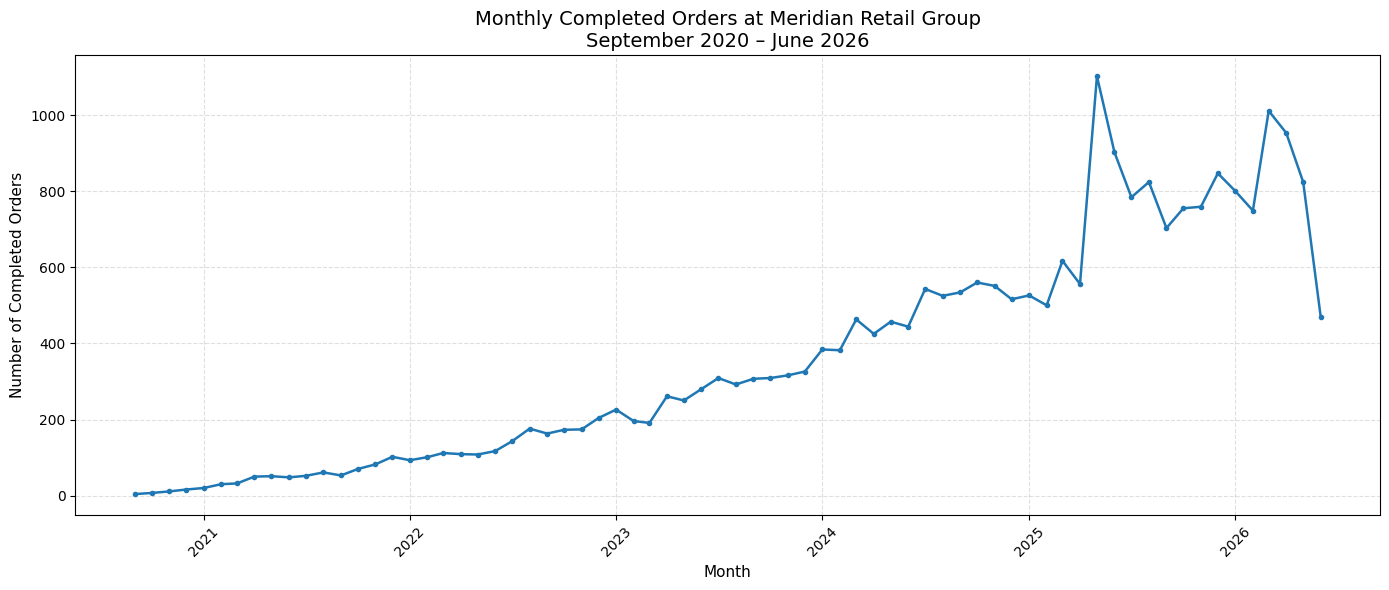

Chart saved to: /content/drive/MyDrive/Meridian_Churn_Capstone/Outputs/Phase_08_Visualizations/04_monthly_completed_order_trend_full_history.png
Months represented: 70


In [16]:
# Chart 4 (revised): Full historical monthly completed-order trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_history["order_month"],
    monthly_history["completed_orders"],
    marker="o",
    markersize=3,
    linewidth=1.8
)

plt.title(
    "Monthly Completed Orders at Meridian Retail Group\n"
    "September 2020 – June 2026"
)
plt.xlabel("Month")
plt.ylabel("Number of Completed Orders")
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(rotation=45)
plt.tight_layout()

# Save as a new file to preserve the original chart
chart_path = OUTPUT_DIR / "04_monthly_completed_order_trend_full_history.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)
print("Months represented:", len(monthly_history))

his chart describes order activity, not customer churn directly. We should not conclude that a change in order volume necessarily means customers are churning.

**Figure 4: Monthly Completed-Order Trend, September 2020–June 2026**

The figure illustrates changes in the monthly number of completed orders at Meridian Retail Group between September 2020 and June 2026. The extended period allows the investigation to identify long-term patterns, periods of increased or reduced transaction activity, and possible fluctuations in customer purchasing behaviour. These patterns provide useful context for the customer churn investigation. However, changes in order volume alone do not establish the causes of churn, and the final month's activity should be interpreted with consideration for data completeness.

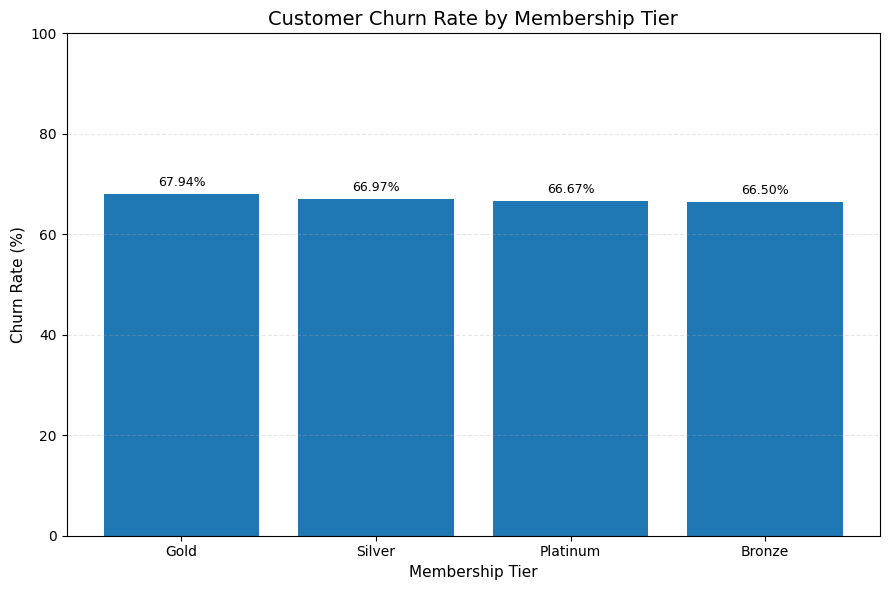

Corrected chart saved to: /content/drive/MyDrive/Meridian_Churn_Capstone/Outputs/Phase_08_Visualizations/01_churn_by_membership_tier_corrected.png
membership_tier  total_customers  churned_customers  churn_rate
           Gold             1126                765       67.94
         Silver             1768               1184       66.97
       Platinum              411                274       66.67
         Bronze             2785               1852       66.50


In [17]:
# Corrected Chart 1: Churn rate by membership tier
# Use a zero-based percentage axis to avoid exaggerating small differences.

tier_summary = (
    customer_analysis
    .groupby("membership_tier", dropna=False)
    .agg(
        total_customers=("customer_id", "nunique"),
        churned_customers=("churned", "sum")
    )
    .reset_index()
)

tier_summary["churn_rate"] = (
    tier_summary["churned_customers"]
    / tier_summary["total_customers"] * 100
)

tier_summary = tier_summary.sort_values("churn_rate", ascending=False)

plt.figure(figsize=(9, 6))
bars = plt.bar(
    tier_summary["membership_tier"].astype(str),
    tier_summary["churn_rate"]
)

plt.title("Customer Churn Rate by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.3)

for bar, rate in zip(bars, tier_summary["churn_rate"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

corrected_chart_path = (
    OUTPUT_DIR / "01_churn_by_membership_tier_corrected.png"
)
plt.savefig(corrected_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Corrected chart saved to:", corrected_chart_path)
print(tier_summary.to_string(index=False))

In [18]:
# Corrected Chart 6: Historical purchase frequency vs monetary value
# Measurement period: all recorded completed orders before 1 July 2026.

orders_for_chart = orders.copy()

orders_for_chart["order_date"] = pd.to_datetime(
    orders_for_chart["order_date"], errors="coerce"
)
orders_for_chart["total_amount"] = pd.to_numeric(
    orders_for_chart["total_amount"], errors="coerce"
)

historical_completed = orders_for_chart[
    orders_for_chart["order_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("completed")
    & orders_for_chart["order_date"].notna()
    & (orders_for_chart["order_date"] < SNAPSHOT_DATE)
].copy()

customer_purchasing = (
    historical_completed
    .groupby("customer_id")
    .agg(
        purchase_frequency=("order_id", "nunique"),
        monetary_value=("total_amount", "sum")
    )
    .reset_index()
)

# Include customers with no recorded completed orders before the snapshot.
chart6_data = customer_analysis[
    ["customer_id", "churn_status"]
].drop_duplicates().merge(
    customer_purchasing,
    on="customer_id",
    how="left"
)

chart6_data["purchase_frequency"] = (
    chart6_data["purchase_frequency"].fillna(0)
)
chart6_data["monetary_value"] = (
    chart6_data["monetary_value"].fillna(0)
)

# Summarize the historical purchasing measures by churn status.
chart6_summary = (
    chart6_data
    .groupby("churn_status")
    .agg(
        customers=("customer_id", "nunique"),
        average_frequency=("purchase_frequency", "mean"),
        average_monetary=("monetary_value", "mean")  )
    .reset_index()
)

print("Chart 6 measurement period:")
print("All recorded completed orders before", SNAPSHOT_DATE.date())
print("\nCustomer purchase summary:")
print(chart6_summary.round(2).to_string(index=False))
fig = px.scatter(
    chart6_data,
    x="purchase_frequency",
    y="monetary_value",
    color="churn_status",
    hover_data=["customer_id"],
    title="Historical Purchase Frequency vs. Spending by Churn Status",
    labels={
        "purchase_frequency": "Completed Orders Before Snapshot",
        "monetary_value": "Total Completed-Order Value Before Snapshot",
        "churn_status": "Customer Status",
        "customer_id": "Customer ID"
    },
    opacity=0.65
)

fig.update_layout(
    xaxis_title="Number of Completed Orders Before 1 July 2026",
    yaxis_title="Total Completed-Order Value Before 1 July 2026"
)

chart6_path = (
    OUTPUT_DIR / "06_interactive_frequency_vs_spending_corrected.html"
)
fig.write_html(chart6_path, include_plotlyjs=True)
fig.show()

print("\nCorrected interactive chart saved to:", chart6_path)

Chart 6 measurement period:
All recorded completed orders before 2026-07-01

Customer purchase summary:
churn_status  customers  average_frequency  average_monetary
      Active       2015               4.80          7,430.43
     Churned       4075               3.78          5,792.67



Corrected interactive chart saved to: /content/drive/MyDrive/Meridian_Churn_Capstone/Outputs/Phase_08_Visualizations/06_interactive_frequency_vs_spending_corrected.html
